In [ ]:
#loading the csv file
from google.colab import files

uploaded=files.upload()
path=list(uploaded.keys())[0]

Mounted at /content/drive


In [ ]:
import pandas as pd

data=pd.read_csv(path
                 )
data.head()

,Marital status,Application mode,Application order,Course,Daytime/evening attendance\t,Previous qualification,Previous qualification (grade),Nacionality,Mother's qualification,Father's qualification,...,Curricular units 2nd sem (credited),Curricular units 2nd sem (enrolled),Curricular units 2nd sem (evaluations),Curricular units 2nd sem (approved),Curricular units 2nd sem (grade),Curricular units 2nd sem (without evaluations),Unemployment rate,Inflation rate,GDP,Target
0,1,17,5,171,1,1,122.0,1,19,12,...,0,0,0,0,0.000000,0,10.8,1.4,1.74,Dropout
1,1,15,1,9254,1,1,160.0,1,1,3,...,0,6,6,6,13.666667,0,13.9,-0.3,0.79,Graduate
2,1,1,5,9070,1,1,122.0,1,37,37,...,0,6,0,0,0.000000,0,10.8,1.4,1.74,Dropout
3,1,17,2,9773,1,1,122.0,1,38,37,...,0,6,10,5,12.400000,0,9.4,-0.8,-3.12,Graduate
4,2,39,1,8014,0,1,100.0,1,37,38,...,0,6,6,6,13.000000,0,13.9,-0.3,0.79,Graduate


In [ ]:
data["Target"].value_counts()

,count
Target,
Graduate,2209
Dropout,1421
Enrolled,794


In [ ]:
data.shape

**Data Preprocessing**

In [ ]:
#importing libraries

import numpy as np
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder

Feature vector and target vector:

In [ ]:
X = data.drop("Target", axis= 1)
y= data["Target"].replace({'Graduate': 0, 'Dropout':1, 'Enrolled':2}).astype(int)

/tmp/ipykernel_1031/4261324535.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  y= data["Target"].replace({'Graduate': 0, 'Dropout':1, 'Enrolled':2}).astype(int)


In [ ]:
#define categorical columns
categorical_cols = [
    "Marital status",
    "Application mode",
    "Application order",
    "Course",
    "Previous qualification",
    "Nacionality",
    "Mother's qualification",
    "Father's qualification",
    "Mother's occupation",
    "Father's occupation"
]

**Splitting data and One-Hot Encoding**

In [ ]:
#do one hot encoding
from sklearn.preprocessing import OneHotEncoder

X_train_pre, X_test_pre, y_train, y_test=train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
    )

encoder=OneHotEncoder(sparse_output=False, handle_unknown='ignore')

X_train_encoded=encoder.fit_transform(X_train_pre[categorical_cols])
X_test_encoded=encoder.transform(X_test_pre[categorical_cols])


X_train_df=pd.DataFrame(X_train_encoded, columns=encoder.get_feature_names_out(categorical_cols))
X_test_df=pd.DataFrame(X_test_encoded, columns=encoder.get_feature_names_out(categorical_cols))

X_train_pre = X_train_pre.reset_index(drop=True)
X_test_pre = X_test_pre.reset_index(drop=True)

X_train_en=pd.concat([X_train_pre.drop(categorical_cols, axis=1), X_train_df],axis=1)
X_test_en=pd.concat([X_test_pre.drop(categorical_cols, axis=1), X_test_df],axis=1)


**Balancing**

In [ ]:
#Balancing
from imblearn.over_sampling import RandomOverSampler , SMOTE
from imblearn.under_sampling import RandomUnderSampler

#undersampling
undersampler= RandomUnderSampler(sampling_strategy= 'auto', random_state= 42)
X_resampled_under, y_resampled_under = undersampler.fit_resample(X_train_en, y_train)


# smote method
smote= SMOTE(sampling_strategy = 'auto', random_state= 42)
X_resampled_smote, y_resampled_smote = smote.fit_resample(X_train_en, y_train)


In [ ]:
y_resampled_under.value_counts()

,count
Target,
0,635
1,635
2,635


In [ ]:
y_resampled_smote.value_counts()


,count
Target,
0,1767
1,1767
2,1767


**Scaling and normalisation**

In [ ]:
#normalization and splitting data into training and testing

#imbalanced data
scaler= StandardScaler()
X_train=scaler.fit_transform(X_train_en)
X_test=scaler.transform(X_test_en)

#undersampled data
scaler_under= StandardScaler()
X_train_under=scaler_under.fit_transform(X_resampled_under)

#smote data
scaler_smote= StandardScaler()
X_train_smote=scaler_smote.fit_transform(X_resampled_smote)


**Import libariies SVM**

In [ ]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import numpy as np

**SVM with Imbalanced Data Using linear kernel**

**For multi class classificaition using SVM -> Use OvO approach for small number of classes it is more accurate than OvA**

https://www.geeksforgeeks.org/machine-learning/multi-class-classification-using-support-vector-machines-svm/

**Linear kernel - Imbalance data**

In [ ]:
print('Imbalance data - Model accuracy score with kernel = linear,C =1: {0:0.4f}'. format(accuracy_score(y_test, y_pred1)))

print('Imbalance data - Model accuracy score with kernel = linear,C =10: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

print('Imbalance data - Model accuracy score with kernel = linear,C =100: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

In [ ]:
# Imbalance data - linear kernel - C =1
linear_svm =SVC(kernel ='linear',decision_function_shape= 'ovo',C= 1)


linear_svm.fit(X_train, y_train)

y_pred1= linear_svm.predict(X_test)

print('Imbalance data - Model accuracy score with kernel = linear,C =1: {0:0.4f}'. format(accuracy_score(y_test, y_pred1)))

Imbalance data - Model accuracy score with kernel = linear,C =1: 0.7650


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linear_svm.score(X_train, y_train)))
print("Test set score : {:.4f}".format(linear_svm.score(X_test, y_test)))

Training set score : 0.8240
Test set score : 0.7650


**Imbalance data - Linear kernel - C =1 - confusion matrix**


[[389  24  29]
 [ 16 231  37]
 [ 65  37  57]]


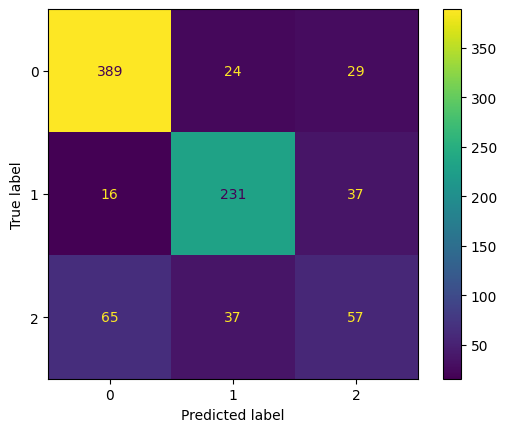

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred1)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred1)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred1))

              precision    recall  f1-score   support

           0       0.83      0.88      0.85       442
           1       0.79      0.81      0.80       284
           2       0.46      0.36      0.40       159

    accuracy                           0.76       885
   macro avg       0.69      0.68      0.69       885
weighted avg       0.75      0.76      0.76       885



In [ ]:
# Imbalance data - linear kernel - C =10
linear_svm100= SVC(kernel ='linear',decision_function_shape= 'ovo',C= 10)


linear_svm100.fit(X_train, y_train)

y_pred= linear_svm100.predict(X_test)

print('Imbalance data - Model accuracy score with kernel = linear, C =10: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Imbalance data - Model accuracy score with kernel = linear, C =10: 0.7593


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linear_svm.score(X_train, y_train)))
print("Test set score : {:.4f}".format(linear_svm.score(X_test, y_test)))

Training set score : 0.8240
Test set score : 0.7650


**Imbalance data - Linear kernel - C =10 - confusion matrix**


[[385  25  32]
 [ 16 229  39]
 [ 63  38  58]]


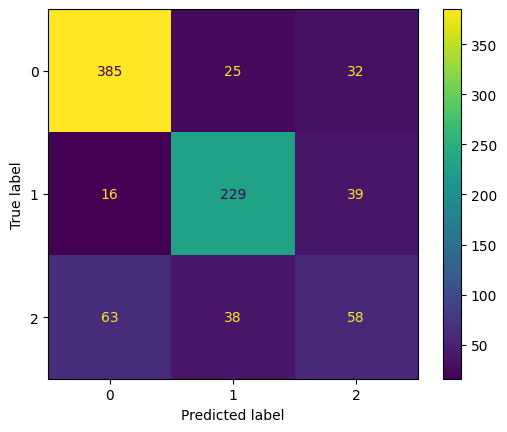

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.83      0.87      0.85       442
           1       0.78      0.81      0.80       284
           2       0.45      0.36      0.40       159

    accuracy                           0.76       885
   macro avg       0.69      0.68      0.68       885
weighted avg       0.75      0.76      0.75       885



In [ ]:
# Imbalance data - linear kernel - C =100
linear_svm1000= SVC(kernel ='linear',decision_function_shape= 'ovo',C= 100)


linear_svm1000.fit(X_train, y_train)

y_pred= linear_svm1000.predict(X_test)

print('Imbalance data - Model accuracy score with kernel = linear, C =100: {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Imbalance data - Model accuracy score with kernel = linear, C =100: 0.7605


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linear_svm.score(X_train, y_train)))
print("Test set score : {:.4f}".format(linear_svm.score(X_test, y_test)))

**Imbalance data - Linear kernel - C =100 - confusion matrix**


In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred1)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred1)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred))

**Linear kernel with Undersampling**

In [ ]:
# Undersampling method - linear kernel - C =1
linearunder_svm = SVC(kernel = 'linear', C= 1, decision_function_shape='ovo' )

linearunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under1= linearunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with linear kernel, C = 1  {0:0.4f}'. format(accuracy_score(y_test, y_pred1)))

Undersampling data - Model Accuracy score with linear kernel, C = 1  0.7650


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linearunder_svm.score(X_train_under, y_resampled_under)))
print("Test set score : {:.4f}".format(linearunder_svm.score(X_test, y_test)))

Training set score : 0.7958
Test set score : 0.6780


**Undersampling method - Linear matrix - C = 1 - Confusion matrix**

[[284  32 126]
 [ 10 220  54]
 [ 26  37  96]]


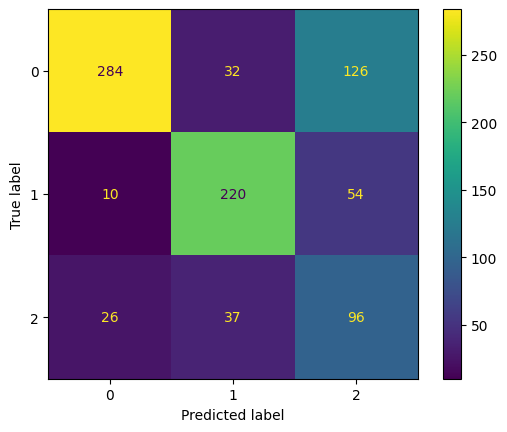

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under1)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under1)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under1))

              precision    recall  f1-score   support

           0       0.89      0.64      0.75       442
           1       0.76      0.77      0.77       284
           2       0.35      0.60      0.44       159

    accuracy                           0.68       885
   macro avg       0.67      0.67      0.65       885
weighted avg       0.75      0.68      0.70       885



In [ ]:
# Undersampling method - linear kernel - C =10
linearunder_svm = SVC(kernel = 'linear', C= 10, decision_function_shape='ovo' )

linearunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= linearunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with linear kernel, C = 10  {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Undersampling data - Model Accuracy score with linear kernel, C = 10  0.7593


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linearunder_svm.score(X_train_under, y_resampled_under)))
print("Test set score : {:.4f}".format(linearunder_svm.score(X_test, y_test)))

Training set score : 0.8005
Test set score : 0.6712


**Undersampling method - Linear matrix - C = 10 - Confusion matrix**

[[279  31 132]
 [ 10 220  54]
 [ 27  37  95]]


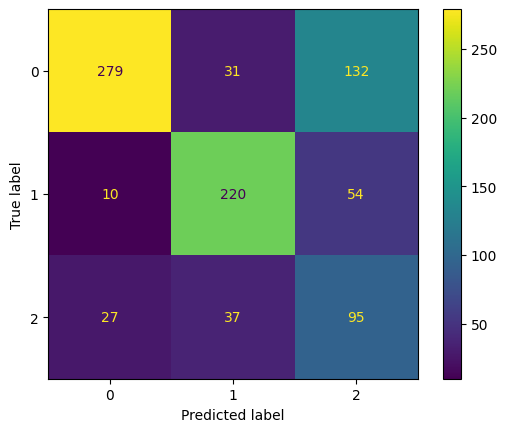

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under))

              precision    recall  f1-score   support

           0       0.88      0.63      0.74       442
           1       0.76      0.77      0.77       284
           2       0.34      0.60      0.43       159

    accuracy                           0.67       885
   macro avg       0.66      0.67      0.65       885
weighted avg       0.75      0.67      0.69       885



In [ ]:
# Undersampling method - linear kernel - C =100
linearunder_svm = SVC(kernel = 'linear', C= 100, decision_function_shape='ovo' )

linearunder_svm.fit(X_train_under, y_resampled_under)

y_pred_under= linearunder_svm.predict(X_test)

print('Undersampling data - Model Accuracy score with linear kernel, C = 100  {0:0.4f}'. format(accuracy_score(y_test, y_pred)))

Undersampling data - Model Accuracy score with linear kernel, C = 100  0.7593


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linearunder_svm.score(X_train_under, y_resampled_under)))
print("Test set score : {:.4f}".format(linearunder_svm.score(X_test, y_test)))

Training set score : 0.8005
Test set score : 0.6655


**Undersampling method - Linear matrix - C = 100 - Confusion matrix**

[[278  33 131]
 [ 13 217  54]
 [ 28  37  94]]


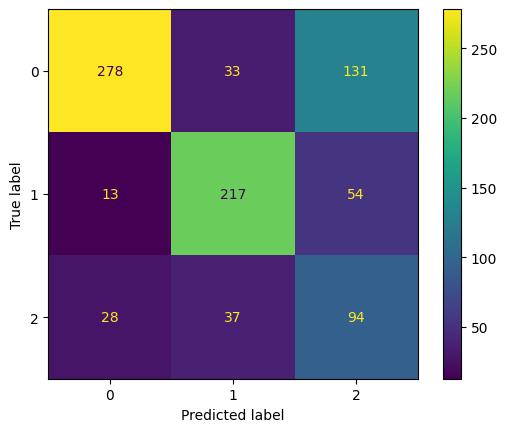

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_under)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_under)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_under))

              precision    recall  f1-score   support

           0       0.87      0.63      0.73       442
           1       0.76      0.76      0.76       284
           2       0.34      0.59      0.43       159

    accuracy                           0.67       885
   macro avg       0.65      0.66      0.64       885
weighted avg       0.74      0.67      0.69       885



**SMOTE method - linear kernel**

In [ ]:
# SMOTE method - linear kernel - C =1
linearsmote_svm = SVC(kernel = 'linear', C=1, decision_function_shape='ovo')

linearsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote1 = linearsmote_svm.predict(X_test)

print("SMOTE method - Model Accuracy with linear kernel , C = 1 is : {0:0.4f}". format(accuracy_score(y_test, y_pred_smote1)))

SMOTE method - Model Accuracy with linear kernel , C = 1 is : 0.6565


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linearsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score : {:.4f}".format(linearsmote_svm.score(X_test, y_test)))

Training set score : 0.8217
Test set score : 0.6565


[[271  37 134]
 [  8 216  60]
 [ 31  34  94]]


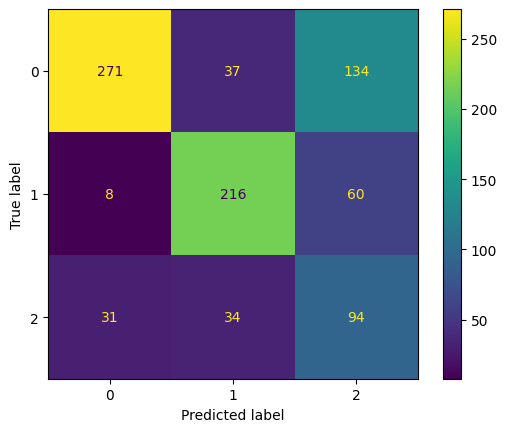

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote1)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote1)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote1))

              precision    recall  f1-score   support

           0       0.87      0.61      0.72       442
           1       0.75      0.76      0.76       284
           2       0.33      0.59      0.42       159

    accuracy                           0.66       885
   macro avg       0.65      0.65      0.63       885
weighted avg       0.74      0.66      0.68       885



In [ ]:
# SMOTE method - linear kernel - C =10
linearsmote_svm = SVC(kernel = 'linear', C=10, decision_function_shape='ovo')

linearsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote = linearsmote_svm.predict(X_test)

print("SMOTE method - Model Accuracy with linear kernel , C = 10 is : {0:0.4f}". format(accuracy_score(y_test, y_pred_smote)))

SMOTE method - Model Accuracy with linear kernel , C = 10 is : 0.6373


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linearsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score : {:.4f}".format(linearsmote_svm.score(X_test, y_test)))

Training set score : 0.8246
Test set score : 0.6373


[[251  37 154]
 [  8 214  62]
 [ 25  35  99]]


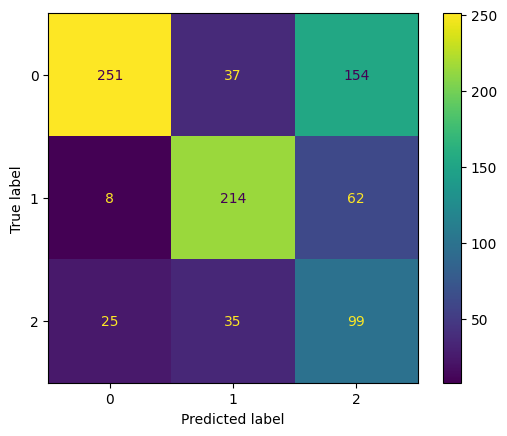

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.88      0.57      0.69       442
           1       0.75      0.75      0.75       284
           2       0.31      0.62      0.42       159

    accuracy                           0.64       885
   macro avg       0.65      0.65      0.62       885
weighted avg       0.74      0.64      0.66       885



In [ ]:
# SMOTE method - linear kernel - C =100
linearsmote_svm = SVC(kernel = 'linear', C=100, decision_function_shape='ovo')

linearsmote_svm.fit(X_train_smote, y_resampled_smote)

y_pred_smote = linearsmote_svm.predict(X_test)

print("SMOTE method - Model Accuracy with linear kernel , C = 100 is : {0:0.4f}". format(accuracy_score(y_test, y_pred_smote)))

SMOTE method - Model Accuracy with linear kernel , C = 100 is : 0.6034


In [ ]:
## checking for overfitting:
print("Training set score : {:.4f}".format (linearsmote_svm.score(X_train_smote, y_resampled_smote)))
print("Test set score : {:.4f}".format(linearsmote_svm.score(X_test, y_test)))

Training set score : 0.8251
Test set score : 0.6034


[[219  33 190]
 [  7 207  70]
 [ 21  30 108]]


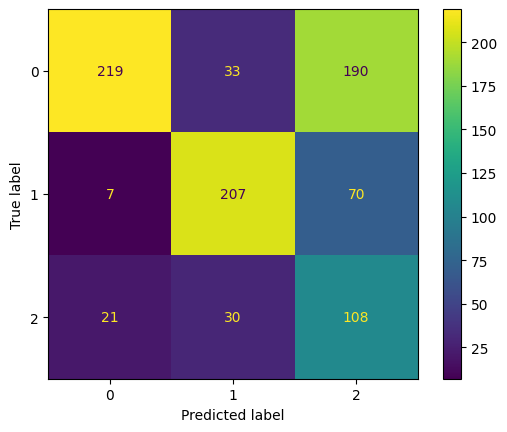

In [ ]:
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm= confusion_matrix(y_test, y_pred_smote)
print(cm)

ConfusionMatrixDisplay.from_predictions(y_test, y_pred_smote)
plt.show()

In [ ]:
from sklearn.metrics import classification_report

print(classification_report(y_test, y_pred_smote))

              precision    recall  f1-score   support

           0       0.89      0.50      0.64       442
           1       0.77      0.73      0.75       284
           2       0.29      0.68      0.41       159

    accuracy                           0.60       885
   macro avg       0.65      0.63      0.60       885
weighted avg       0.74      0.60      0.63       885

